# B-Spline Quadratic Hash Encoding Matched Instant-NGP Hyperparameter Run

This notebook trains the hashed quadratic B-spline NeRF once, using the same dataset path, output layout, metrics, and comparison-relevant hyperparameters as the matched Instant-NGP and linear B-spline single-run notebooks.


In [ ]:
# Optional: mount Google Drive when running on Colab.
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
except Exception as e:
    print("Drive mount skipped or already mounted:", e)


Mounted at /content/drive


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import numpy as np
import os
import imageio
import torch.nn as nn
from tqdm import tqdm

import json, csv, time, random, platform, shutil
from datetime import datetime


In [ ]:
#Check GPU
import torch

print(torch.cuda.is_available())
print(torch.cuda.device_count())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

True
1
NVIDIA A100-SXM4-40GB


In [ ]:
def get_rays(datapath, mode='train'):

    pose_file_names = [f for f in os.listdir(datapath + f'/{mode}/pose') if f.endswith('.txt')]
    intrisics_file_names = [f for f in os.listdir(datapath + f'/{mode}/intrinsics') if f.endswith('.txt')]
    img_file_names = [f for f in os.listdir(datapath + '/imgs') if mode in f]

    assert len(pose_file_names) == len(intrisics_file_names)
    assert len(img_file_names) == len(pose_file_names)

    # Read
    N = len(pose_file_names)
    poses = np.zeros((N, 4, 4))
    intrinsics = np.zeros((N, 4, 4))

    images = []

    for i in range(N):
        name = pose_file_names[i]

        pose = open(datapath + f'/{mode}/pose/' + name).read().split()
        poses[i] = np.array(pose, dtype=float).reshape(4, 4)

        intrinsic = open(datapath + f'/{mode}/intrinsics/' + name).read().split()
        intrinsics[i] = np.array(intrinsic, dtype=float).reshape(4, 4)

        # Read images
        img = imageio.imread(datapath + '/imgs/' + name.replace('txt', 'png')) / 255.
        images.append(img[None, ...])
    images = np.concatenate(images)

    H = images.shape[1]
    W = images.shape[2]

    if images.shape[3] == 4: #RGBA -> RGB
        images = images[..., :3] * images[..., -1:] + (1 - images[..., -1:])

    rays_o = np.zeros((N, H*W, 3))
    rays_d = np.zeros((N, H*W, 3))
    target_px_values = images.reshape((N, H*W, 3))

    for i in range(N):

        c2w = poses[i]
        f = intrinsics[i, 0, 0]

        u = np.arange(W)
        v = np.arange(H)
        u, v = np.meshgrid(u, v)
        dirs = np.stack((u - W / 2, -(v - H / 2), - np.ones_like(u) * f), axis=-1)
        dirs = (c2w[:3, :3] @ dirs[..., None]).squeeze(-1)
        dirs = dirs / np.linalg.norm(dirs, axis=-1, keepdims=True)

        rays_d[i] = dirs.reshape(-1, 3)
        rays_o[i] += c2w[:3, 3]

    return rays_o, rays_d, target_px_values

In [ ]:
def bspline_basis_quadratic(u):
    """
    u : [B] in [0,1)
    returns quadratic B-spline weights [B,3]
    """
    w0 = 0.5 * (1 - u) ** 2
    w1 = 0.75 - (u - 0.5) ** 2
    w2 = 0.5 * u ** 2
    return torch.stack([w0, w1, w2], dim=-1)


In [ ]:
import torch
import torch.nn as nn

@torch.jit.script
def fast_hash_3d(ix: torch.Tensor, iy: torch.Tensor, iz: torch.Tensor, table_size: int):
    """
    Instant-NGP-matched hash function.

    This matches the hash used in the Instant-NGP and matched linear B-spline notebooks:
        h(i,j,k) = i*1 + j*2654435761 + k*805459861  mod table_size

    The quadratic encoder still differs from linear/trilinear interpolation because it uses
    degree-2 B-spline basis weights and a 3x3x3 stencil.
    """
    h = ix * 1 + iy * 2_654_435_761 + iz * 805_459_861
    return (h % table_size).to(torch.long)


In [ ]:
class HashedQuadraticBSplineField(nn.Module):
    """
    Multilevel hashed grid encoding using quadratic tensor-product B-spline interpolation.

    Matched to the Instant-NGP/linear run in hyperparameters: same number of
    levels, feature dimension, base resolution, hash table size, hash function,
    per-level scale, and downstream MLP. The intended difference is only the
    degree-2 B-spline basis and its 3x3x3 stencil.

    The rendering function already maps samples into [0,1], so xyz is expected in [0,1].
    Each level uses a 3 x 3 x 3 stencil, giving 27 hashed feature lookups per level.
    """

    def __init__(
        self,
        n_levels=12,
        base_resolution=16,
        feat_dim=2,
        degree=2,
        table_size=2**15,
        per_level_scale=2.0,
    ):
        super().__init__()
        assert degree == 2, "This class is written for quadratic degree-2 B-splines."

        self.n_levels = n_levels
        self.base_resolution = base_resolution
        self.feat_dim = feat_dim
        self.degree = degree
        self.hashmap_size = table_size if isinstance(table_size, int) else None
        self.base_res = base_resolution
        self.per_level_scale = per_level_scale

        self.resolutions = [
            int(base_resolution * (per_level_scale ** l))
            for l in range(n_levels)
        ]

        if isinstance(table_size, int):
            self.table_sizes = [table_size] * n_levels
        else:
            assert len(table_size) == n_levels
            self.table_sizes = list(table_size)

        self.tables = nn.ParameterList()
        for T in self.table_sizes:
            self.tables.append(nn.Parameter(torch.randn(T, feat_dim) * 0.01))

        # 27 offsets for the quadratic stencil
        offsets = [[i, j, k] for i in range(3)
                               for j in range(3)
                               for k in range(3)]
        self.register_buffer("offsets", torch.tensor(offsets, dtype=torch.long))

    def forward(self, xyz: torch.Tensor):
        B = xyz.shape[0]

        # Samples are already normalized to [0,1] in rendering().
        x = xyz

        feats = []

        for table, R, T in zip(self.tables, self.resolutions, self.table_sizes):
            s = x * R
            base = torch.floor(s).long()
            frac = s - base.float()

            wx = bspline_basis_quadratic(frac[:, 0])
            wy = bspline_basis_quadratic(frac[:, 1])
            wz = bspline_basis_quadratic(frac[:, 2])

            idx = base[:, None, :] + self.offsets[None, :, :]

            gx = idx[:, :, 0].contiguous()
            gy = idx[:, :, 1].contiguous()
            gz = idx[:, :, 2].contiguous()

            h = fast_hash_3d(gx, gy, gz, T)
            cp = table[h]  # [B,27,F]

            w = (
                wx[:, :, None, None] *
                wy[:, None, :, None] *
                wz[:, None, None, :]
            ).reshape(B, 27, 1)

            feat = (cp * w).sum(dim=1)
            feats.append(feat)

        return torch.cat(feats, dim=-1)



In [ ]:
class NerfSpline(nn.Module):
    """
    Quadratic B-spline NeRF matched to the Instant-NGP single-run architecture.

    Comparison-relevant settings are matched to Instant-NGP/linear B-spline:
    hidden width, levels, features per level, hash table size/function,
    base resolution, per-level scale, density activation, and color branch.

    The conceptual/technical difference is the encoder basis:
    degree-2 tensor-product B-spline interpolation over a 3x3x3 stencil.
    """

    def __init__(
        self,
        hidden_dim=128,
        n_levels=12,
        feat_per_level=2,
        base_resolution=16,
        table_size=2**15,
        per_level_scale=2.0,
    ):
        super().__init__()

        self.encoder = HashedQuadraticBSplineField(
            n_levels=n_levels,
            base_resolution=base_resolution,
            feat_dim=feat_per_level,
            degree=2,
            table_size=table_size,
            per_level_scale=per_level_scale,
        )

        enc_out_dim = n_levels * feat_per_level

        # Same MLP structure as the Instant-NGP notebook.
        self.trunk = nn.Sequential(
            nn.Linear(enc_out_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )

        self.sigma_head = nn.Linear(hidden_dim, 1)
        self.feature_head = nn.Linear(hidden_dim, hidden_dim)

        self.color_mlp = nn.Sequential(
            nn.Linear(hidden_dim + 3, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, 3),
            nn.Sigmoid()
        )

    def forward(self, xyz, d):
        phi = self.encoder(xyz)
        h = self.trunk(phi)

        # Same density activation as the Instant-NGP and matched linear notebooks.
        sigma = F.softplus(self.sigma_head(h)).squeeze(-1)

        feat = self.feature_head(h)
        rgb = self.color_mlp(torch.cat([feat, d], dim=-1))

        return rgb, sigma

    def intersect(self, x, d):
        return self.forward(x, d)


In [ ]:
def training(model, optimizer, scheduler, tn, tf, nb_bins, nb_epochs, data_loader, device='cpu'):

    training_loss = []
    psnr = []
    for epoch in (range(nb_epochs)):
        for batch in tqdm(data_loader):
            o = batch[:, :3].to(device)
            print("Batch shape:", batch.shape)
            d = batch[:, 3:6].to(device)

            target = batch[:, 6:].to(device)

            prediction = rendering(model, o, d, tn, tf, nb_bins=nb_bins, device=device)

            loss = ((prediction - target)**2).mean()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            training_loss.append(loss.item())
            psnr.append(20 * np.log10(1.0 / np.sqrt(loss.item())))

        scheduler.step()

        torch.save(model.cpu(), 'model_nerf')
        model.to(device)

    return training_loss, psnr

In [ ]:
def compute_accumulated_transmittance(betas):
    accumulated_transmittance = torch.cumprod(betas, 1)
    return torch.cat((torch.ones(accumulated_transmittance.shape[0], 1, device=accumulated_transmittance.device),
                      accumulated_transmittance[:, :-1]), dim=1)

In [ ]:
def rendering(model, rays_o, rays_d, tn, tf, nb_bins=100, device='cpu', white_bckgr=True):

    # ---- cache t_vals + delta so they are not recomputed every batch ----
    if not hasattr(rendering, "cache"):
        rendering.cache = {}

    key = (tn, tf, nb_bins, device)

    if key not in rendering.cache:
        t_vals = torch.linspace(tn, tf, nb_bins, device=device)
        delta = torch.cat(
            (t_vals[1:] - t_vals[:-1],
             torch.tensor([1e10], device=device))
        )
        rendering.cache[key] = (t_vals, delta)

    t_vals, delta = rendering.cache[key]
    # ---------------------------------------------------------------------

    rays_d = rays_d / (torch.norm(rays_d, dim=-1, keepdim=True) + 1e-9)

    x = rays_o.unsqueeze(1) + \
        t_vals.unsqueeze(0).unsqueeze(-1) * rays_d.unsqueeze(1)

    x = (x / tf) * 0.5 + 0.5

    colors, density = model.intersect(
        x.reshape(-1, 3),
        rays_d.expand(x.shape[1], x.shape[0], 3)
              .transpose(0, 1)
              .reshape(-1, 3)
    )

    colors = colors.reshape((x.shape[0], nb_bins, 3))
    density = density.reshape((x.shape[0], nb_bins))

    alpha = 1 - torch.exp(-density * delta.unsqueeze(0))

    weights = compute_accumulated_transmittance(1 - alpha) * alpha

    c = (weights.unsqueeze(-1) * colors).sum(1)

    if white_bckgr:
        weight_sum = weights.sum(-1)
        return c + 1 - weight_sum.unsqueeze(-1)
    else:
        return c

In [ ]:
def psnr_from_mse(mse: float, max_val: float = 1.0) -> float:
    mse = max(mse, 1e-12)
    return 20.0 * np.log10(max_val / np.sqrt(mse))

def save_checkpoint(path, model, optimizer, scheduler, epoch, *, tn, tf, nb_bins, extra=None):
    ckpt = {
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optim_state": optimizer.state_dict() if optimizer is not None else None,
        "sched_state": scheduler.state_dict() if scheduler is not None else None,
        "params": {"tn": tn, "tf": tf, "nb_bins": nb_bins},
        "extra": extra or {},
    }
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    torch.save(ckpt, path)

def load_checkpoint(path, model, optimizer=None, scheduler=None, map_location="cpu"):
    ckpt = torch.load(path, map_location=map_location)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None and ckpt.get("optim_state") is not None:
        optimizer.load_state_dict(ckpt["optim_state"])
    if scheduler is not None and ckpt.get("sched_state") is not None:
        scheduler.load_state_dict(ckpt["sched_state"])
    return ckpt  # contains epoch + params too

def train_single_epoch(
    model,
    optimizer,
    scheduler,
    tn,
    tf,
    nb_bins,
    data_loader,
    *,
    device="cpu",
    epoch_idx=0,
    ckpt_dir="checkpoints",
    ckpt_name_prefix="nerf",
    save_every_epoch=True,
):
    model.train()
    model.to(device)

    epoch_losses = []
    epoch_psnr = []

    for batch in tqdm(data_loader, desc=f"epoch {epoch_idx}"):
        batch = batch.to(device)  # assumes batch is a tensor
        o = batch[:, :3]
        d = batch[:, 3:6]
        target = batch[:, 6:]

        prediction = rendering(model, o, d, tn, tf, nb_bins=nb_bins, device=device)
        loss = ((prediction - target) ** 2).mean()

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        mse = float(loss.detach().item())
        epoch_losses.append(mse)
        epoch_psnr.append(psnr_from_mse(mse))

    if scheduler is not None:
        scheduler.step()

    if save_every_epoch:
        ckpt_path = os.path.join(
            ckpt_dir,
            f"{ckpt_name_prefix}_epoch{epoch_idx:04d}_tn{tn}_tf{tf}_bins{nb_bins}.pt",
        )
        save_checkpoint(
            ckpt_path,
            model,
            optimizer,
            scheduler,
            epoch_idx,
            tn=tn,
            tf=tf,
            nb_bins=nb_bins,
            extra={"mean_loss": float(np.mean(epoch_losses))},
        )

    return epoch_losses, epoch_psnr

## Single-run configuration


In [ ]:
# -----------------------------
# Single run configuration
# -----------------------------
SEED = 42

# Dataset path
DATASET_PATH = "/content/drive/MyDrive/Thesis/Papers Implemented/fox"

# Output path: this run folder will contain images, checkpoints, logs, plots, and metadata.
EXPERIMENT_ROOT = "/content/drive/MyDrive/Thesis/Papers Implemented/experiments"
RUN_NAME = "bspline_quadratic_hashed_matched_instant_ngp"

# Training parameters
BATCH_SIZE = 1024
NB_EPOCHS = 10
LR = 1e-4
GAMMA = 0.5
MILESTONES = [5, 10]
TN = 8.0
TF = 12.0
NB_BINS = 100

# Image/render parameters
H = 400
W = 400
TEST_IMAGE_INDEX = 0
RENDER_CHUNK_SIZE = 4096   # rays per render chunk; lower this if you get CUDA OOM

# Model parameters
HIDDEN_DIM = 128
N_LEVELS = 12
FEAT_PER_LEVEL = 2
LOG2_HASHMAP_SIZE = 15
BASE_RESOLUTION = 16
TABLE_SIZE = 2**LOG2_HASHMAP_SIZE
PER_LEVEL_SCALE = 2.0

# Safety/performance switches
SAVE_CHECKPOINT_EVERY_EPOCH = True
SAVE_FINAL_MODEL_STATE = True

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR = os.path.join(EXPERIMENT_ROOT, f"{RUN_NAME}_{timestamp}")
IMG_DIR = os.path.join(RUN_DIR, "epoch_images")
CKPT_DIR = os.path.join(RUN_DIR, "checkpoints")
PLOT_DIR = os.path.join(RUN_DIR, "plots")

for d in [RUN_DIR, IMG_DIR, CKPT_DIR, PLOT_DIR]:
    os.makedirs(d, exist_ok=True)

config = {
    "method": "Hashed quadratic B-spline multiresolution encoding matched to Instant-NGP hyperparameters",
    "run_name": RUN_NAME,
    "timestamp": timestamp,
    "seed": SEED,
    "dataset_path": DATASET_PATH,
    "batch_size": BATCH_SIZE,
    "nb_epochs": NB_EPOCHS,
    "learning_rate": LR,
    "scheduler": {"type": "MultiStepLR", "milestones": MILESTONES, "gamma": GAMMA},
    "tn": TN,
    "tf": TF,
    "nb_bins": NB_BINS,
    "image_height": H,
    "image_width": W,
    "test_image_index": TEST_IMAGE_INDEX,
    "render_chunk_size": RENDER_CHUNK_SIZE,
    "hidden_dim": HIDDEN_DIM,
    "n_levels": N_LEVELS,
    "feat_per_level": FEAT_PER_LEVEL,
    "base_resolution": BASE_RESOLUTION,
    "log2_hashmap_size": LOG2_HASHMAP_SIZE,
    "table_size": TABLE_SIZE,
    "per_level_scale": PER_LEVEL_SCALE,
    "device": device,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "python": platform.python_version(),
    "torch": torch.__version__,
}

with open(os.path.join(RUN_DIR, "config.json"), "w") as f:
    json.dump(config, f, indent=2)

print("Run directory:", RUN_DIR)



Device: cuda
GPU: NVIDIA A100-SXM4-40GB
Run directory: /content/drive/MyDrive/Thesis/Papers Implemented/experiments/bspline_quadratic_hashed_matched_instant_ngp_20260603_105419


In [ ]:
# -----------------------------
# Load train/test rays
# -----------------------------
o, d, target_px_values = get_rays(DATASET_PATH, mode="train")

train_tensor = torch.cat((
    torch.from_numpy(o).reshape(-1, 3).float(),
    torch.from_numpy(d).reshape(-1, 3).float(),
    torch.from_numpy(target_px_values).reshape(-1, 3).float()
), dim=1)

dataloader = DataLoader(
    train_tensor,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device == "cuda"),
)

test_o, test_d, test_target_px_values = get_rays(DATASET_PATH, mode="test")

dataset_summary = {
    "train_images": int(o.shape[0]),
    "test_images": int(test_o.shape[0]),
    "height": H,
    "width": W,
    "train_rays": int(train_tensor.shape[0]),
    "train_batches_per_epoch": int(len(dataloader)),
}

with open(os.path.join(RUN_DIR, "dataset_summary.json"), "w") as f:
    json.dump(dataset_summary, f, indent=2)

print(dataset_summary)


/tmp/ipykernel_2763/3129188668.py:27: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imageio.imread(datapath + '/imgs/' + name.replace('txt', 'png')) / 255.


{'train_images': 90, 'test_images': 10, 'height': 400, 'width': 400, 'train_rays': 14400000, 'train_batches_per_epoch': 14063}


In [ ]:
# -----------------------------
# Extra helpers for logging
# -----------------------------
def count_parameters(model):
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))

def save_json(path, data):
    with open(path, "w") as f:
        json.dump(data, f, indent=2)

def append_jsonl(path, item):
    with open(path, "a") as f:
        f.write(json.dumps(item) + "\n")

def write_metrics_csv(path, rows):
    if not rows:
        return
    fieldnames = list(rows[0].keys())
    with open(path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

def mse2psnr(mse: float, max_val: float = 1.0) -> float:
    mse = max(float(mse), 1e-12)
    return 20.0 * np.log10(max_val / np.sqrt(mse))

@torch.no_grad()
def render_image_from_rays_chunked(
    model,
    o_np,
    d_np,
    *,
    tn: float,
    tf: float,
    nb_bins: int,
    chunk_size: int,
    H: int,
    W: int,
    target_np=None,
    device: str = "cuda",
):
    """Renders one full image from rays. Here chunk_size means rays per chunk."""
    model.to(device)
    model.eval()

    o_t = torch.from_numpy(o_np).float()
    d_t = torch.from_numpy(d_np).float()

    rgb_chunks = []
    for start in tqdm(range(0, o_t.shape[0], chunk_size), desc="render", leave=False):
        end = min(start + chunk_size, o_t.shape[0])
        o_b = o_t[start:end].to(device)
        d_b = d_t[start:end].to(device)
        rgb_b = rendering(model, o_b, d_b, tn, tf, nb_bins=nb_bins, device=device)
        rgb_chunks.append(rgb_b.detach().cpu())

    image_np = torch.cat(rgb_chunks, dim=0).reshape(H, W, 3).numpy()
    image_np = np.clip(image_np, 0.0, 1.0)

    mse = psnr = None
    if target_np is not None:
        tgt = np.asarray(target_np)
        if tgt.ndim == 2 and tgt.shape[-1] == 3:
            tgt = tgt.reshape(H, W, 3)
        mse = float(((image_np - tgt) ** 2).mean())
        psnr = float(mse2psnr(mse))

    return image_np, mse, psnr

def save_epoch_image(image_np, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    imageio.imwrite(path, (np.clip(image_np, 0.0, 1.0) * 255).astype(np.uint8))

def save_metric_plots(rows):
    epochs = [r["epoch"] for r in rows]

    plt.figure()
    plt.plot(epochs, [r["train_mean_psnr"] for r in rows], marker="o", label="train mean PSNR")
    plt.plot(epochs, [r["test_psnr"] for r in rows], marker="o", label="test PSNR")
    plt.xlabel("Epoch")
    plt.ylabel("PSNR (dB)")
    plt.legend()
    plt.grid(True)
    plt.savefig(os.path.join(PLOT_DIR, "psnr_by_epoch.png"), dpi=200, bbox_inches="tight")
    plt.show()

    plt.figure()
    plt.plot(epochs, [r["train_mean_loss"] for r in rows], marker="o")
    plt.xlabel("Epoch")
    plt.ylabel("Mean training MSE")
    plt.grid(True)
    plt.savefig(os.path.join(PLOT_DIR, "loss_by_epoch.png"), dpi=200, bbox_inches="tight")
    plt.show()


{'class': 'NerfSpline', 'trainable_parameters': 831428, 'encoder_class': 'HashedQuadraticBSplineField', 'encoder_n_levels': 12, 'encoder_feat_dim': 2, 'encoder_hashmap_size': 32768, 'encoder_base_res': 16, 'encoder_base_resolution': 16, 'encoder_per_level_scale': 2.0, 'encoder_table_sizes': [32768, 32768, 32768, 32768, 32768, 32768, 32768, 32768, 32768, 32768, 32768, 32768], 'encoder_resolutions': [16, 32, 64, 128, 256, 512, 1024, 2048, 4096, 8192, 16384, 32768], 'encoder_basis_degree': 2, 'encoder_stencil_size': '3x3x3', 'matched_to': 'Instant-NGP hyperparameters except interpolation degree/stencil'}


epoch 0: 100%|██████████| 14063/14063 [17:50<00:00, 13.13it/s]


Epoch 0000 | train PSNR 25.69 dB | test PSNR 29.57 dB | image saved: epoch_0000_test0_psnr_29.57.png


epoch 1: 100%|██████████| 14063/14063 [17:51<00:00, 13.13it/s]


Epoch 0001 | train PSNR 29.88 dB | test PSNR 30.81 dB | image saved: epoch_0001_test0_psnr_30.81.png


epoch 2: 100%|██████████| 14063/14063 [17:52<00:00, 13.12it/s]


... (11 outputs left out)

epoch 8: 100%|██████████| 14063/14063 [17:50<00:00, 13.13it/s]


Epoch 0008 | train PSNR 32.08 dB | test PSNR 30.69 dB | image saved: epoch_0008_test0_psnr_30.69.png


epoch 9: 100%|██████████| 14063/14063 [17:50<00:00, 13.14it/s]


Epoch 0009 | train PSNR 32.16 dB | test PSNR 30.61 dB | image saved: epoch_0009_test0_psnr_30.61.png


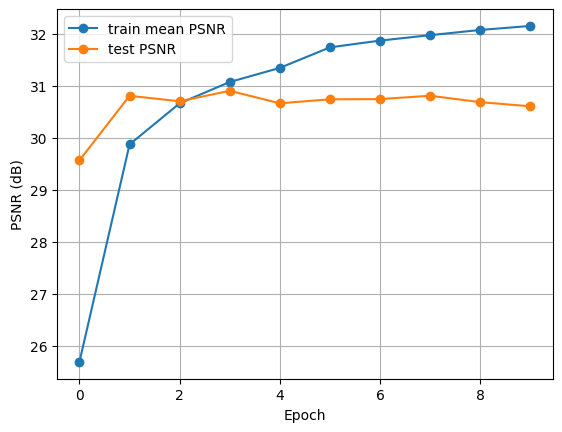

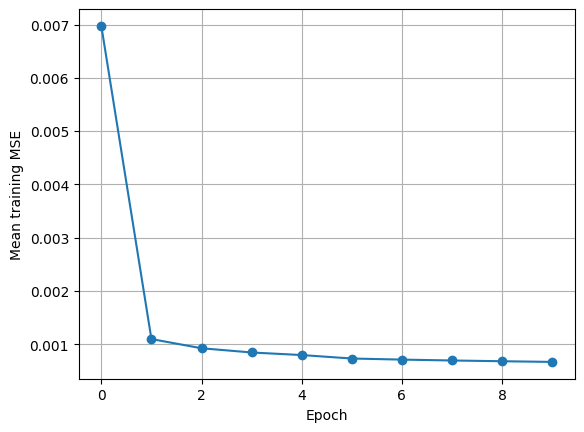

Run complete.
Best test PSNR: 30.90826365666027 at epoch 3
Chapter 4 summary: /content/drive/MyDrive/Thesis/Papers Implemented/experiments/bspline_quadratic_hashed_matched_instant_ngp_20260603_105419/chapter4_summary.json


In [ ]:
# -----------------------------
# Single complete run
# -----------------------------
model = NerfSpline(
    hidden_dim=HIDDEN_DIM,
    n_levels=N_LEVELS,
    feat_per_level=FEAT_PER_LEVEL,
    base_resolution=BASE_RESOLUTION,
    table_size=TABLE_SIZE,
    per_level_scale=PER_LEVEL_SCALE,
).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=MILESTONES, gamma=GAMMA)

model_summary = {
    "class": model.__class__.__name__,
    "trainable_parameters": count_parameters(model),
    "encoder_class": model.encoder.__class__.__name__,
    "encoder_n_levels": int(model.encoder.n_levels),
    "encoder_feat_dim": int(model.encoder.feat_dim),
    "encoder_hashmap_size": int(TABLE_SIZE),
    "encoder_base_res": int(model.encoder.base_res),
    "encoder_base_resolution": int(model.encoder.base_resolution),
    "encoder_per_level_scale": float(model.encoder.per_level_scale),
    "encoder_table_sizes": [int(t) for t in model.encoder.table_sizes],
    "encoder_resolutions": [int(r) for r in model.encoder.resolutions],
    "encoder_basis_degree": 2,
    "encoder_stencil_size": "3x3x3",
    "matched_to": "Instant-NGP hyperparameters except interpolation degree/stencil",
}
save_json(os.path.join(RUN_DIR, "model_summary.json"), model_summary)
print(model_summary)

all_rows = []
all_batch_losses = []
all_batch_psnr = []

metrics_jsonl_path = os.path.join(RUN_DIR, "epoch_metrics.jsonl")

run_start = time.time()

for epoch in range(NB_EPOCHS):
    epoch_start = time.time()

    epoch_losses, epoch_psnr = train_single_epoch(
        model,
        optimizer,
        scheduler,
        TN,
        TF,
        NB_BINS,
        dataloader,
        device=device,
        epoch_idx=epoch,
        ckpt_dir=CKPT_DIR,
        ckpt_name_prefix="bspline_quadratic_matched",
        save_every_epoch=SAVE_CHECKPOINT_EVERY_EPOCH,
    )

    # Render the same held-out test image at the end of every epoch.
    image_np, test_mse, test_psnr = render_image_from_rays_chunked(
        model,
        test_o[TEST_IMAGE_INDEX],
        test_d[TEST_IMAGE_INDEX],
        tn=TN,
        tf=TF,
        nb_bins=NB_BINS,
        chunk_size=RENDER_CHUNK_SIZE,
        H=H,
        W=W,
        target_np=test_target_px_values[TEST_IMAGE_INDEX],
        device=device,
    )

    image_path = os.path.join(IMG_DIR, f"epoch_{epoch:04d}_test{TEST_IMAGE_INDEX}_psnr_{test_psnr:.2f}.png")
    save_epoch_image(image_np, image_path)

    row = {
        "epoch": int(epoch),
        "train_mean_loss": float(np.mean(epoch_losses)),
        "train_mean_psnr": float(np.mean(epoch_psnr)),
        "train_last_loss": float(epoch_losses[-1]),
        "train_last_psnr": float(epoch_psnr[-1]),
        "test_mse": float(test_mse),
        "test_psnr": float(test_psnr),
        "learning_rate": float(optimizer.param_groups[0]["lr"]),
        "epoch_time_sec": float(time.time() - epoch_start),
        "image_path": image_path,
    }

    all_rows.append(row)
    all_batch_losses.extend(epoch_losses)
    all_batch_psnr.extend(epoch_psnr)

    append_jsonl(metrics_jsonl_path, row)
    write_metrics_csv(os.path.join(RUN_DIR, "epoch_metrics.csv"), all_rows)

    torch.save(
        {
            "epoch_metrics": all_rows,
            "batch_losses": all_batch_losses,
            "batch_psnr": all_batch_psnr,
            "config": config,
            "dataset_summary": dataset_summary,
            "model_summary": model_summary,
        },
        os.path.join(RUN_DIR, "metrics.pt"),
    )

    print(
        f"Epoch {epoch:04d} | "
        f"train PSNR {row['train_mean_psnr']:.2f} dB | "
        f"test PSNR {row['test_psnr']:.2f} dB | "
        f"image saved: {os.path.basename(image_path)}"
    )

total_time = time.time() - run_start

if SAVE_FINAL_MODEL_STATE:
    torch.save(model.state_dict(), os.path.join(RUN_DIR, "final_model_state_dict.pt"))

best_row = max(all_rows, key=lambda r: r["test_psnr"])
chapter4_summary = {
    "method": config["method"],
    "dataset": dataset_summary,
    "model": model_summary,
    "training": {
        "epochs": NB_EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LR,
        "nb_bins": NB_BINS,
        "tn": TN,
        "tf": TF,
        "total_time_sec": float(total_time),
    },
    "final_epoch": all_rows[-1],
    "best_test_epoch": best_row,
    "artifacts": {
        "run_dir": RUN_DIR,
        "epoch_metrics_csv": os.path.join(RUN_DIR, "epoch_metrics.csv"),
        "epoch_metrics_jsonl": metrics_jsonl_path,
        "metrics_pt": os.path.join(RUN_DIR, "metrics.pt"),
        "epoch_images_dir": IMG_DIR,
        "checkpoints_dir": CKPT_DIR,
        "plots_dir": PLOT_DIR,
    },
}
save_json(os.path.join(RUN_DIR, "chapter4_summary.json"), chapter4_summary)

save_metric_plots(all_rows)

print("Run complete.")
print("Best test PSNR:", best_row["test_psnr"], "at epoch", best_row["epoch"])
print("Chapter 4 summary:", os.path.join(RUN_DIR, "chapter4_summary.json"))



## Optional: inspect saved table

In [ ]:
# Shows the epoch-wise table inside the notebook after the run.
import pandas as pd
metrics_df = pd.read_csv(os.path.join(RUN_DIR, "epoch_metrics.csv"))
metrics_df


,epoch,train_mean_loss,train_mean_psnr,train_last_loss,train_last_psnr,test_mse,test_psnr,learning_rate,epoch_time_sec,image_path
0,0,0.006973,25.687835,0.000942,30.261185,0.001104,29.569337,0.000100,1072.881805,/content/drive/MyDrive/Thesis/Papers Implement...
1,1,0.001097,29.875598,0.000525,32.802195,0.000829,30.812243,0.000100,1072.876256,/content/drive/MyDrive/Thesis/Papers Implement...
2,2,0.000925,30.667450,0.000798,30.978595,0.000850,30.706979,0.000100,1073.754682,/content/drive/MyDrive/Thesis/Papers Implement...
3,3,0.000845,31.078517,0.000381,34.188982,0.000811,30.908264,0.000100,1073.176689,/content/drive/MyDrive/Thesis/Papers Implement...
4,4,0.000797,31.349582,0.000454,33.426090,0.000857,30.667893,0.000050,1071.945866,/content/drive/MyDrive/Thesis/Papers Implement...
5,5,0.000732,31.745222,0.000917,30.375376,0.000842,30.744708,0.000050,1070.760977,/content/drive/MyDrive/Thesis/Papers Implement...
6,6,0.000712,31.875462,0.000653,31.848540,0.000842,30.748860,0.000050,1071.907421,/content/drive/MyDrive/Thesis/Papers Implement...
7,7,0.000695,31.979980,0.000405,33.924944,0.000829,30.813024,0.000050,1071.496065,/content/drive/MyDrive/Thesis/Papers Implement...
8,8,0.000681,32.080217,0.000283,35.487668,0.000853,30.690065,0.000050,1072.266619,/content/drive/MyDrive/Thesis/Papers Implement...
9,9,0.000668,32.157889,0.000333,34.774583,0.000869,30.609896,0.000025,1071.946274,/content/drive/MyDrive/Thesis/Papers Implement...
